In [1]:
import duckdb
import pandas as pd

# Open in read_only mode so background scripts or app servers can still write/query
con = duckdb.connect("../data/processed/analytics.duckdb", read_only=True)

df_preview = con.execute("""
    SELECT 
        customer_id,
        cohort_month,
        event_date,
        tier,
        mrr,
        event_type
    FROM subscription_events
    ORDER BY customer_id, event_date
    LIMIT 10;
""").df()

df_preview

,customer_id,cohort_month,event_date,tier,mrr,event_type
0,CUST-1001,2024-01,2024-01-21,Starter,29.0,new
1,CUST-1001,2024-01,2024-02-20,Starter,29.0,renew
2,CUST-1001,2024-01,2024-03-21,Starter,29.0,renew
3,CUST-1001,2024-01,2024-04-20,Starter,29.0,renew
4,CUST-1001,2024-01,2024-05-20,Starter,29.0,renew
5,CUST-1001,2024-01,2024-06-19,Starter,29.0,renew
6,CUST-1001,2024-01,2024-07-19,Starter,29.0,renew
7,CUST-1001,2024-01,2024-08-18,Starter,29.0,renew
8,CUST-1001,2024-01,2024-09-17,Starter,29.0,renew
9,CUST-1001,2024-01,2024-10-17,Starter,29.0,renew


In [2]:
con.execute("""
    SELECT 
        tier,
        COUNT(*) as total_events,
        ROUND(AVG(mrr), 2) as avg_mrr,
        COUNT(DISTINCT customer_id) as unique_customers
    FROM subscription_events
    GROUP BY tier
    ORDER BY unique_customers DESC;
""").df()

,tier,total_events,avg_mrr,unique_customers
0,Starter,18308,27.34,3367
1,Pro,11194,93.44,2208
2,Enterprise,5158,287.52,872


In [4]:
from pathlib import Path

# 1. Read the production MRR waterfall SQL query
sql_path = Path("../src/queries/mrr_waterfall.sql")
with open(sql_path, "r") as f:
    mrr_query = f.read()

# 2. Execute against your DuckDB table
df_waterfall = con.execute(mrr_query).df()

# 3. View the financial waterfall
df_waterfall

,ACTIVITY_MONTH,TOTAL_NEW_MRR,TOTAL_EXPANSION_MRR,TOTAL_CONTRACTION_MRR,TOTAL_CHURNED_MRR,NET_NEW_MRR,ENDING_MRR
0,2024-01,23110.0,0.0,0.0,29.0,23081.0,23651.0
1,2024-02,25460.0,620.0,200.0,4205.0,21675.0,44215.0
2,2024-03,20710.0,2920.0,810.0,5462.0,17358.0,63015.0
3,2024-04,24540.0,2910.0,680.0,7304.0,19466.0,81580.0
4,2024-05,23190.0,3060.0,820.0,7447.0,17983.0,102269.0
5,2024-06,22560.0,5000.0,890.0,8295.0,18375.0,117938.0
6,2024-07,22510.0,5770.0,830.0,8327.0,19123.0,141589.0
7,2024-08,22520.0,4820.0,1170.0,9285.0,16885.0,157653.0
8,2024-09,22560.0,6860.0,1960.0,8394.0,19066.0,173012.0
9,2024-10,25050.0,9410.0,1700.0,12684.0,20076.0,199857.0


,activity_month,total_new_mrr,total_expansion_mrr,total_contraction_mrr,total_churned_mrr,net_new_mrr,ending_mrr
0,2024-01,23110.0,0.0,0.0,29.0,23081.0,23651.0
1,2024-02,25460.0,620.0,200.0,4205.0,21675.0,44215.0
2,2024-03,20710.0,2920.0,810.0,5462.0,17358.0,63015.0
3,2024-04,24540.0,2910.0,680.0,7304.0,19466.0,81580.0
4,2024-05,23190.0,3060.0,820.0,7447.0,17983.0,102269.0
5,2024-06,22560.0,5000.0,890.0,8295.0,18375.0,117938.0
6,2024-07,22510.0,5770.0,830.0,8327.0,19123.0,141589.0
7,2024-08,22520.0,4820.0,1170.0,9285.0,16885.0,157653.0
8,2024-09,22560.0,6860.0,1960.0,8394.0,19066.0,173012.0
9,2024-10,25050.0,9410.0,1700.0,12684.0,20076.0,199857.0


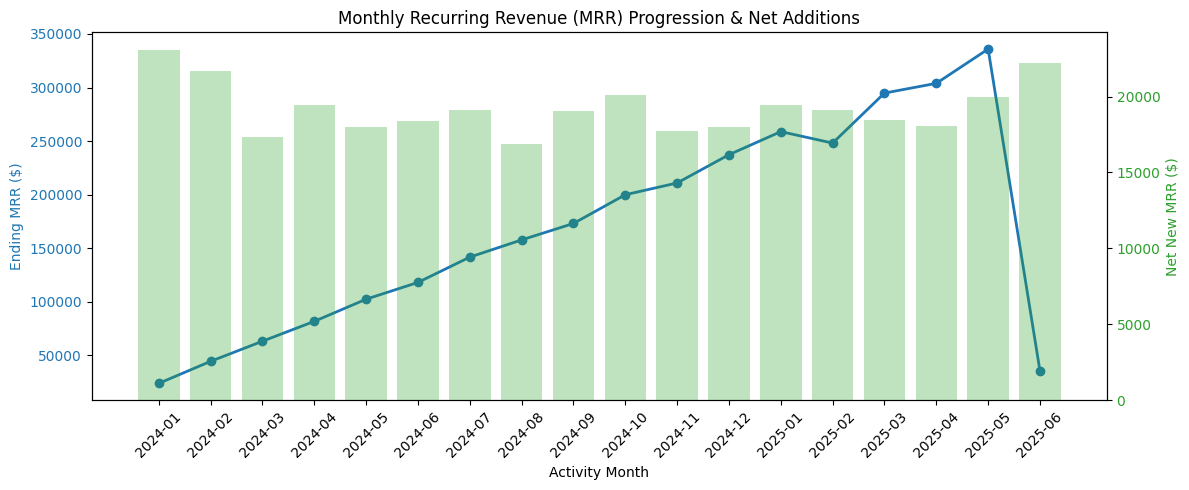

In [7]:
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Read production SQL file
sql_path = Path("../src/queries/mrr_waterfall.sql")
with open(sql_path, "r") as f:
    mrr_query = f.read()

# 2. Execute query against DuckDB
df_waterfall = con.execute(mrr_query).df()

# 3. Ensure lowercase column names to prevent key mismatches
df_waterfall.columns = [col.lower() for col in df_waterfall.columns]

# 4. Display tabular output
display(df_waterfall)

# 5. Plot MRR Progression & Net Additions
fig, ax1 = plt.subplots(figsize=(12, 5))

color = "tab:blue"
ax1.set_xlabel("Activity Month")
ax1.set_ylabel("Ending MRR ($)", color=color)
ax1.plot(
    df_waterfall["activity_month"],
    df_waterfall["ending_mrr"],
    color=color,
    marker="o",
    linewidth=2,
    label="Ending MRR",
)
ax1.tick_params(axis="y", labelcolor=color)
plt.xticks(rotation=45)

ax2 = ax1.twinx()
color = "tab:green"
ax2.set_ylabel("Net New MRR ($)", color=color)
ax2.bar(
    df_waterfall["activity_month"],
    df_waterfall["net_new_mrr"],
    color=color,
    alpha=0.3,
    label="Net New MRR",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Monthly Recurring Revenue (MRR) Progression & Net Additions")
fig.tight_layout()
plt.show()

--- User Retention (%) Matrix ---


tenure_month,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
cohort_month,,,,,,,,,,,,,,,,,,
2024-01,100.0,78.33,77.67,71.33,69.67,68.67,67.67,66.33,64.67,63.0,61.0,59.67,57.33,52.33,55.0,54.0,50.33,3.33
2024-02,100.0,81.67,74.67,70.33,69.67,68.0,66.67,64.67,62.33,60.67,60.0,59.33,54.67,57.0,55.0,55.0,2.0,
2024-03,100.0,80.67,76.0,66.67,64.67,62.67,60.67,56.67,55.0,53.67,51.67,47.67,49.0,47.67,46.67,1.67,,
2024-04,100.0,80.33,73.67,69.33,66.67,65.67,64.33,61.67,61.0,59.0,54.67,56.0,54.33,53.0,1.67,,,
2024-05,100.0,78.67,73.33,66.0,64.0,62.67,61.67,60.67,60.67,56.0,58.67,58.0,57.0,1.0,,,,
2024-06,100.0,81.0,73.33,67.0,65.67,63.67,62.33,61.67,55.33,58.33,57.67,57.0,1.67,,,,,
2024-07,100.0,86.67,81.0,72.0,71.0,69.0,67.0,59.0,63.33,62.67,61.33,2.0,,,,,,
2024-08,100.0,85.0,75.33,66.67,65.67,62.33,55.67,60.0,57.67,56.33,2.33,,,,,,,
2024-09,100.0,80.67,77.0,72.0,71.33,63.0,70.0,68.67,67.67,2.67,,,,,,,,


--- Net Revenue Retention / NRR (%) Matrix ---


tenure_month,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
cohort_month,,,,,,,,,,,,,,,,,,
2024-01,100.0,79.3,80.12,75.24,77.65,81.32,87.22,86.14,82.9,86.85,79.56,79.91,80.75,69.78,78.99,77.54,77.3,4.14
2024-02,100.0,90.16,84.0,83.67,82.72,90.09,88.11,88.2,92.0,88.64,91.1,94.01,84.39,92.87,85.6,91.98,3.63,
2024-03,100.0,84.59,82.6,73.99,77.08,72.66,73.98,75.68,73.78,75.72,72.95,64.93,77.3,73.31,73.98,4.86,,
2024-04,100.0,86.76,83.25,83.96,83.76,80.9,87.38,84.21,88.32,91.26,81.4,90.75,89.43,95.0,2.55,,,
2024-05,100.0,79.73,80.49,76.43,73.72,78.19,77.93,80.98,83.42,80.35,87.04,86.73,89.58,2.63,,,,
2024-06,100.0,83.73,78.34,71.98,71.93,71.18,74.76,74.26,68.1,79.02,77.42,81.1,4.54,,,,,
2024-07,100.0,88.9,85.05,82.83,80.89,85.28,86.89,71.8,83.97,81.08,88.36,2.84,,,,,,
2024-08,100.0,86.41,85.8,75.26,78.96,80.39,71.28,81.52,74.76,76.27,2.14,,,,,,,
2024-09,100.0,86.93,85.06,86.54,93.99,80.63,97.21,98.2,105.65,3.73,,,,,,,,


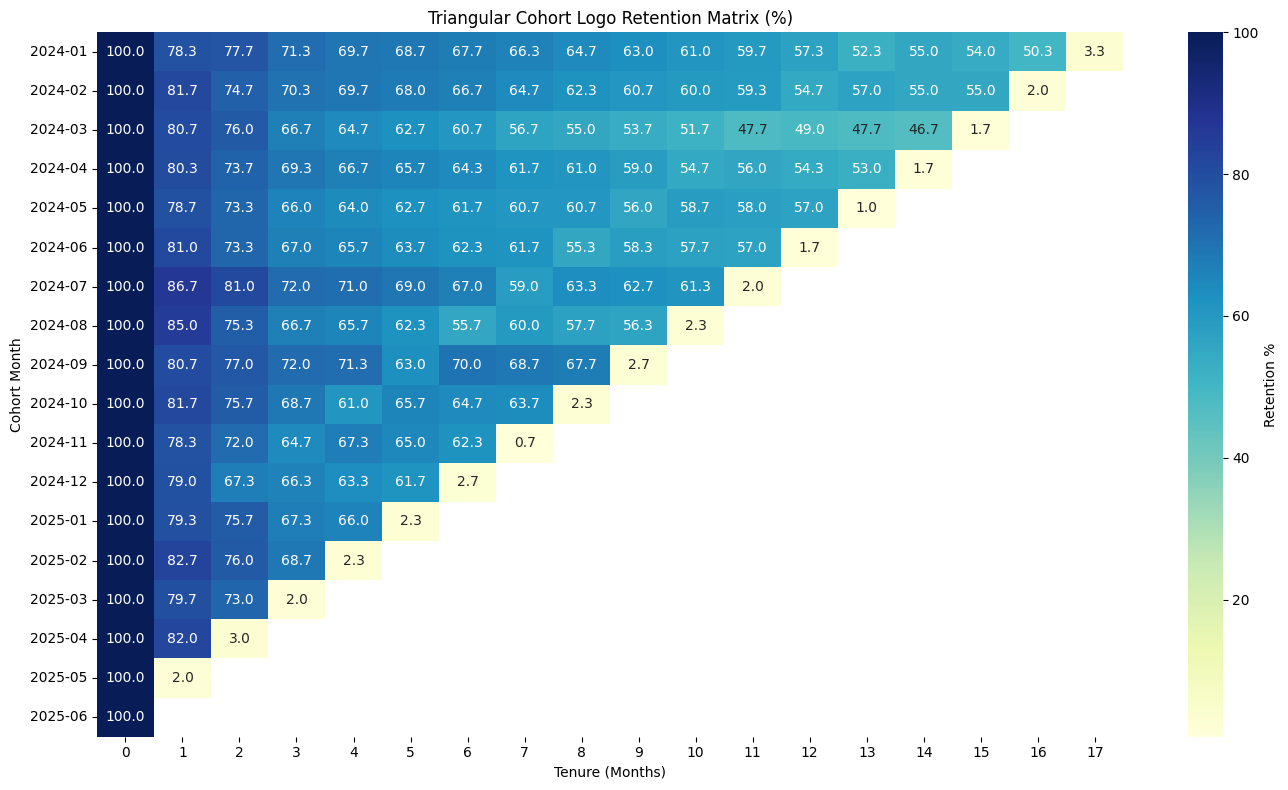

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Read production cohort retention SQL
cohort_sql_path = Path("../src/queries/cohort_retention.sql")
with open(cohort_sql_path, "r") as f:
    cohort_sql = f.read()

# 2. Execute query against DuckDB
df_cohort = con.execute(cohort_sql).df()
df_cohort.columns = [col.lower() for col in df_cohort.columns]

# 3. Pivot into Triangular Logo Retention Matrix
retention_matrix = df_cohort.pivot(
    index="cohort_month", 
    columns="tenure_month", 
    values="user_retention_pct"
)

# 4. Pivot into Triangular Net Revenue Retention (NRR) Matrix
nrr_matrix = df_cohort.pivot(
    index="cohort_month", 
    columns="tenure_month", 
    values="nrr_pct"
)

# 5. Display tabular views
print("--- User Retention (%) Matrix ---")
display(retention_matrix.fillna(""))

print("--- Net Revenue Retention / NRR (%) Matrix ---")
display(nrr_matrix.fillna(""))

# 6. Plot the Logo Retention Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_matrix, 
    annot=True, 
    fmt=".1f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Retention %'}
)
plt.title("Triangular Cohort Logo Retention Matrix (%)")
plt.xlabel("Tenure (Months)")
plt.ylabel("Cohort Month")
plt.tight_layout()
plt.show()